In [1]:
import pandas as pd

movies = pd.read_csv("data/movies.csv")
ratings = pd.read_csv("data/ratings.csv")

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)

Movies shape: (9742, 3)
Ratings shape: (100836, 4)


In [2]:
display(movies.head())
display(ratings.head())

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [3]:
print("Movies information:")
movies.info()

print("\nRatings information:")
ratings.info()

Movies information:
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB

Ratings information:
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [4]:
print("Missing values in movies:")
print(movies.isnull().sum())

print("\nMissing values in ratings:")
print(ratings.isnull().sum())


Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [5]:
print("Number of unique users:", ratings["userId"].nunique())
print("Number of unique movies rated:", ratings["movieId"].nunique())
print("Average rating:", ratings["rating"].mean())
print("Minimum rating:", ratings["rating"].min())
print("Maximum rating:", ratings["rating"].max())

Number of unique users: 610
Number of unique movies rated: 9724
Average rating: 3.501556983616962
Minimum rating: 0.5
Maximum rating: 5.0


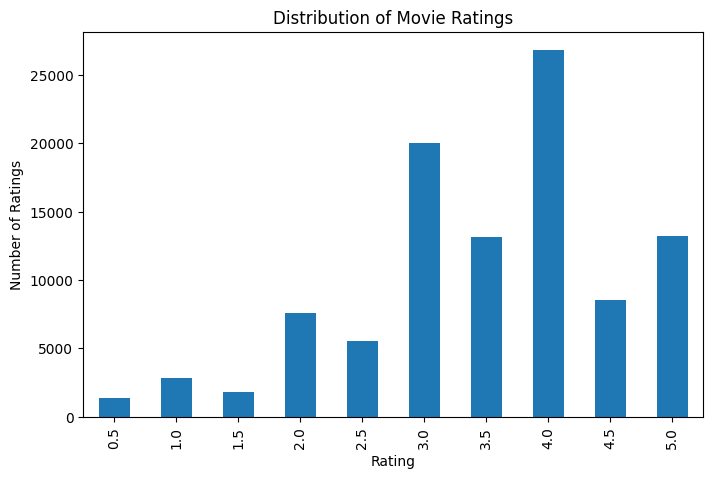

In [6]:
import matplotlib.pyplot as plt

ratings["rating"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Distribution of Movie Ratings")
plt.show()

In [7]:
user_rating_counts = ratings.groupby("userId").size()
movie_rating_counts = ratings.groupby("movieId").size()

print("Average ratings per user:", user_rating_counts.mean())
print("Maximum ratings by one user:", user_rating_counts.max())

print("Average ratings per movie:", movie_rating_counts.mean())
print("Maximum ratings for one movie:", movie_rating_counts.max())

Average ratings per user: 165.30491803278687
Maximum ratings by one user: 2698
Average ratings per movie: 10.369806663924312
Maximum ratings for one movie: 329


In [8]:
movie_popularity = (
    ratings.groupby("movieId").size()
    .sort_values(ascending=False)
)
popular_movies_ids = movie_popularity.head(10).index


In [9]:
popular_movies = movies[movies["movieId"].isin(popular_movies_ids)]
print(popular_movies)

      movieId                                      title  \
97        110                          Braveheart (1995)   
224       260  Star Wars: Episode IV - A New Hope (1977)   
257       296                        Pulp Fiction (1994)   
277       318           Shawshank Redemption, The (1994)   
314       356                        Forrest Gump (1994)   
418       480                       Jurassic Park (1993)   
461       527                    Schindler's List (1993)   
507       589          Terminator 2: Judgment Day (1991)   
510       593           Silence of the Lambs, The (1991)   
1939     2571                         Matrix, The (1999)   

                                genres  
97                    Action|Drama|War  
224            Action|Adventure|Sci-Fi  
257        Comedy|Crime|Drama|Thriller  
277                        Crime|Drama  
314           Comedy|Drama|Romance|War  
418   Action|Adventure|Sci-Fi|Thriller  
461                          Drama|War  
507        

In [10]:
genres_1 = movies["genres"].str.split("|").explode()
print(genres_1.nunique())
print(genres_1.unique())

20
<StringArray>
[         'Adventure',          'Animation',           'Children',
             'Comedy',            'Fantasy',            'Romance',
              'Drama',             'Action',              'Crime',
           'Thriller',             'Horror',            'Mystery',
             'Sci-Fi',                'War',            'Musical',
        'Documentary',               'IMAX',            'Western',
          'Film-Noir', '(no genres listed)']
Length: 20, dtype: str


In [11]:
genre_matrix = movies["genres"].str.get_dummies(sep="|")
genre_matrix.head()

,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,0,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [12]:
genre_matrix.insert(0, "movieId", movies["movieId"])
print(genre_matrix)

      movieId  (no genres listed)  Action  Adventure  Animation  Children  \
0           1                   0       0          1          1         1   
1           2                   0       0          1          0         1   
2           3                   0       0          0          0         0   
3           4                   0       0          0          0         0   
4           5                   0       0          0          0         0   
...       ...                 ...     ...        ...        ...       ...   
9737   193581                   0       1          0          1         0   
9738   193583                   0       0          0          1         0   
9739   193585                   0       0          0          0         0   
9740   193587                   0       1          0          1         0   
9741   193609                   0       0          0          0         0   

      Comedy  Crime  Documentary  Drama  ...  Film-Noir  Horror  IMAX  \
0 

In [13]:
from sklearn.metrics.pairwise import cosine_similarity

In [14]:
similarity_matrix = cosine_similarity(
    genre_matrix.drop("movieId",axis=1)
)

In [15]:
print(similarity_matrix.shape)

(9742, 9742)


In [16]:
def recommended_movies(movie_title,n=10):
    movie_index = movies.index[movies["title"] == movie_title][0]
    similarity_scores = similarity_matrix[movie_index]
    similar_movies = similarity_scores.argsort()[::-1]
    similar_movies = similar_movies[similar_movies!=movie_index]
    top_movies = similar_movies[:n]
    recommended_movies = movies.iloc[top_movies]
    return recommended_movies

In [17]:
recommended_movies("Jumanji (1995)")

,movieId,title,genres
8800,130450,Pan (2015),Adventure|Children|Fantasy
8719,126142,The Cave of the Golden Rose (1991),Adventure|Children|Fantasy
6075,41566,"Chronicles of Narnia: The Lion, the Witch and ...",Adventure|Children|Fantasy
6751,59501,"Chronicles of Narnia: Prince Caspian, The (2008)",Adventure|Children|Fantasy
6389,50601,Bridge to Terabithia (2007),Adventure|Children|Fantasy
6655,56915,"Water Horse: Legend of the Deep, The (2007)",Adventure|Children|Fantasy
7478,82169,Chronicles of Narnia: The Voyage of the Dawn T...,Adventure|Children|Fantasy
7426,80748,Alice in Wonderland (1933),Adventure|Children|Fantasy
9336,160573,Pete's Dragon (2016),Adventure|Children|Fantasy
9294,158813,Alice Through the Looking Glass (2016),Adventure|Children|Fantasy
